### 1 Data Loading & EDA

#### Dataset Source and Description
The dataset used in this project is the **Breast Cancer Wisconsin (Diagnostic)** dataset, obtained from the [UCI Machine Learning Repository](https://archive.ics.uci.edu/ml/datasets/Breast+Cancer+Wisconsin+%28Diagnostic%29). 

The dataset contains 30 numerical features calculated from digitized images of fine needle aspirate (FNA) procedures of breast masses. These features describe the geometric and morphological characteristics of the **cell nuclei** present in the tissue sample (such as radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry, and fractal dimension).

In [1]:
import warnings
import pandas as pd
import numpy as np

# Ignore all warnings for a cleaner output
warnings.filterwarnings('ignore')


# Define column names according to the dataset documentation (wdbc.names)
# Column 0: ID, Column 1: Diagnosis (M = Malignant, B = Benign)
# Columns 2 to 31: 30 cellular characteristics (10 features measured in 3 variants: mean, se, worst)
feature_names = [
    'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean',
    'compactness_mean', 'concavity_mean', 'concave_points_mean', 'symmetry_mean', 'fractal_dimension_mean',
    'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se',
    'compactness_se', 'concavity_se', 'concave_points_se', 'symmetry_se', 'fractal_dimension_se',
    'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst',
    'compactness_worst', 'concavity_worst', 'concave_points_worst', 'symmetry_worst', 'fractal_dimension_worst'
]

columns = ['id', 'diagnosis'] + feature_names


# Read the wdbc.data file (although it has a .data extension, it is comma-separated internally)
df = pd.read_csv('wdbc.data', header=None, names=columns)

# Display the first 5 records of the dataset
print("\n--- FIRST 5 ROWS ---")
display(df.head())

# Check general info, data types, and non-null counts
print("\n--- DATASET INFO & MISSING VALUES ---")
df.info()

# Check descriptive statistics for numerical features
print("\n--- DESCRIPTIVE STATISTICS ---")
display(df.describe().T[['mean', 'std', 'min', 'max']])




--- FIRST 5 ROWS ---


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678



--- DATASET INFO & MISSING VALUES ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave_points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    

,mean,std,min,max
id,3.037183e+07,1.250206e+08,8670.000000,9.113205e+08
radius_mean,1.412729e+01,3.524049e+00,6.981000,2.811000e+01
texture_mean,1.928965e+01,4.301036e+00,9.710000,3.928000e+01
perimeter_mean,9.196903e+01,2.429898e+01,43.790000,1.885000e+02
area_mean,6.548891e+02,3.519141e+02,143.500000,2.501000e+03
smoothness_mean,9.636028e-02,1.406413e-02,0.052630,1.634000e-01
compactness_mean,1.043410e-01,5.281276e-02,0.019380,3.454000e-01
concavity_mean,8.879932e-02,7.971981e-02,0.000000,4.268000e-01
concave_points_mean,4.891915e-02,3.880284e-02,0.000000,2.012000e-01
symmetry_mean,1.811619e-01,2.741428e-02,0.106000,3.040000e-01


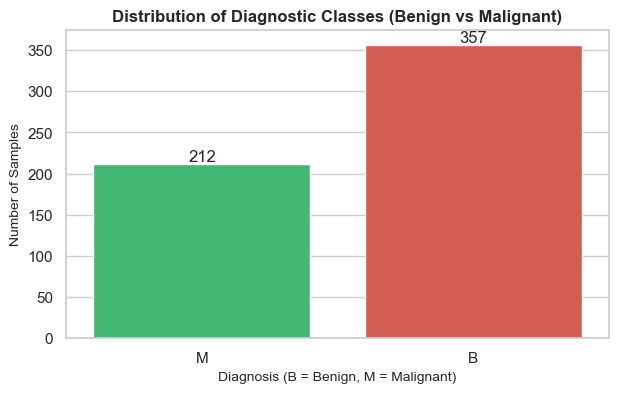

Class Counts:
diagnosis
B    357
M    212
Name: count, dtype: int64

Class Percentages (%):
diagnosis
B    62.741652
M    37.258348
Name: proportion, dtype: float64


In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set the visual style
sns.set_theme(style="whitegrid")

# Plotting the class distribution
plt.figure(figsize=(7, 4))
ax = sns.countplot(x='diagnosis', hue='diagnosis', data=df, palette=['#2ecc71', '#e74c3c'], legend=False)
plt.title('Distribution of Diagnostic Classes (Benign vs Malignant)', fontsize=12, fontweight='bold')
plt.xlabel('Diagnosis (B = Benign, M = Malignant)', fontsize=10)
plt.ylabel('Number of Samples', fontsize=10)

# Display counts on top of the bars
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='center', 
                xytext=(0, 5), 
                textcoords='offset points')

plt.show()

# Print exact counts and percentages for a complete report
print("Class Counts:")
print(df['diagnosis'].value_counts())
print("\nClass Percentages (%):")
print(df['diagnosis'].value_counts(normalize=True) * 100)

## 2. Preprocessing and Data Cleaning
Before performing exploratory analysis and modeling, the dataset undergoes structural cleaning: verifying the absence of null values, removing the non-informative identifier (`id`), encoding the categorical target (`diagnosis`) into binary values (`0` and `1`), and separating raw features (`X`) from the target vector (`y`).

In [3]:
from sklearn.preprocessing import LabelEncoder
import pandas as pd

# ==========================================
# 1. DATA CLEANING & PREPROCESSING
# ==========================================

# Explicitly check for missing or null values across all columns
print("--- MISSING VALUES CHECK ---")
missing_values = df.isnull().sum()
total_missing = missing_values.sum()
print(f"Total missing values in the dataset: {total_missing}")

if total_missing > 0:
    print("Columns with missing values:")
    print(missing_values[missing_values > 0])
else:
    print("Verification passed: No missing values found in the dataset.")

# Drop the 'id' column (and 'Unnamed: 32' if present) as they have no predictive power
cols_to_drop = [col for col in ['id', 'Unnamed: 32'] if col in df.columns]
if cols_to_drop:
    df.drop(columns=cols_to_drop, inplace=True)
    print("\n--- COLUMNS DROPPED ---")
    print(f"Removed columns: {cols_to_drop}")

# Encode the target variable 'diagnosis' ('M' -> 1 for Malignant, 'B' -> 0 for Benign)
label_encoder = LabelEncoder()
df['diagnosis'] = label_encoder.fit_transform(df['diagnosis'])

# Calculate both absolute counts and percentages for a complete view
counts = df['diagnosis'].value_counts()
percentages = df['diagnosis'].value_counts(normalize=True) * 100



# ==========================================
# 2. FEATURE-TARGET SEPARATION (RAW DATA)
# ==========================================
# Note: We keep X in raw (unscaled) form. Data splitting (5%, 15%, 25% test sizes) 
# and scaling via Pipeline will be executed in the Modeling section to prevent data leakage.
X = df.drop(columns=['diagnosis'])
y = df['diagnosis']

print(f"\nFeatures shape (X): {X.shape}")
print(f"Target shape (y): {y.shape}")

--- MISSING VALUES CHECK ---
Total missing values in the dataset: 0
Verification passed: No missing values found in the dataset.

--- COLUMNS DROPPED ---
Removed columns: ['id']

Features shape (X): (569, 30)
Target shape (y): (569,)


#### Preprocessing & Class Distribution Summary
* **Data Integrity:** The dataset contains zero missing values across all 569 records. The non-predictive `id` column was removed, leaving 30 numerical features (`X`) and 1 encoded target variable (`y`, where `0 = Benign` and `1 = Malignant`).
* **Class Balance:** The target distribution shows **357 Benign cases (62.74%)** and **212 Malignant cases (37.26%)**. Because there is a moderate class imbalance, subsequent splits and cross-validation steps will use stratification to preserve these proportions.

# 3. Multicollinearity Analysis, PCA, and Outliers

This section examines feature multicollinearity using a correlation matrix, performs an exploratory Principal Component Analysis (PCA), and evaluates extreme values (outliers) across the dataset.

### Methodological Considerations & Biological Context
* **Exploratory PCA vs. Modeling Pipeline (Preventing Data Leakage):** The PCA visualization presented below is fitted on the global dataset **solely for exploratory and illustrative purposes** to observe variance distribution and class separability in two dimensions. To prevent data leakage during model training and evaluation, `StandardScaler` and `PCA` are **never** fitted globally prior to splitting; instead, they are encapsulated inside a Scikit-learn `Pipeline` fitted strictly on `X_train` and applied to `X_test`.
* **Outliers & Nuclear Morphology:** Extreme values observed in geometric and morphological features (such as `area_mean`, `radius_worst`, or `concavity_mean`) are not treated as measurement errors, nor do they automatically equate to malignancy. Rather, they reflect natural biological variability and the pronounced pleomorphism (irregular size, contour, and chromatin distribution) of **cell nuclei** commonly present in advanced or aggressive tumors.

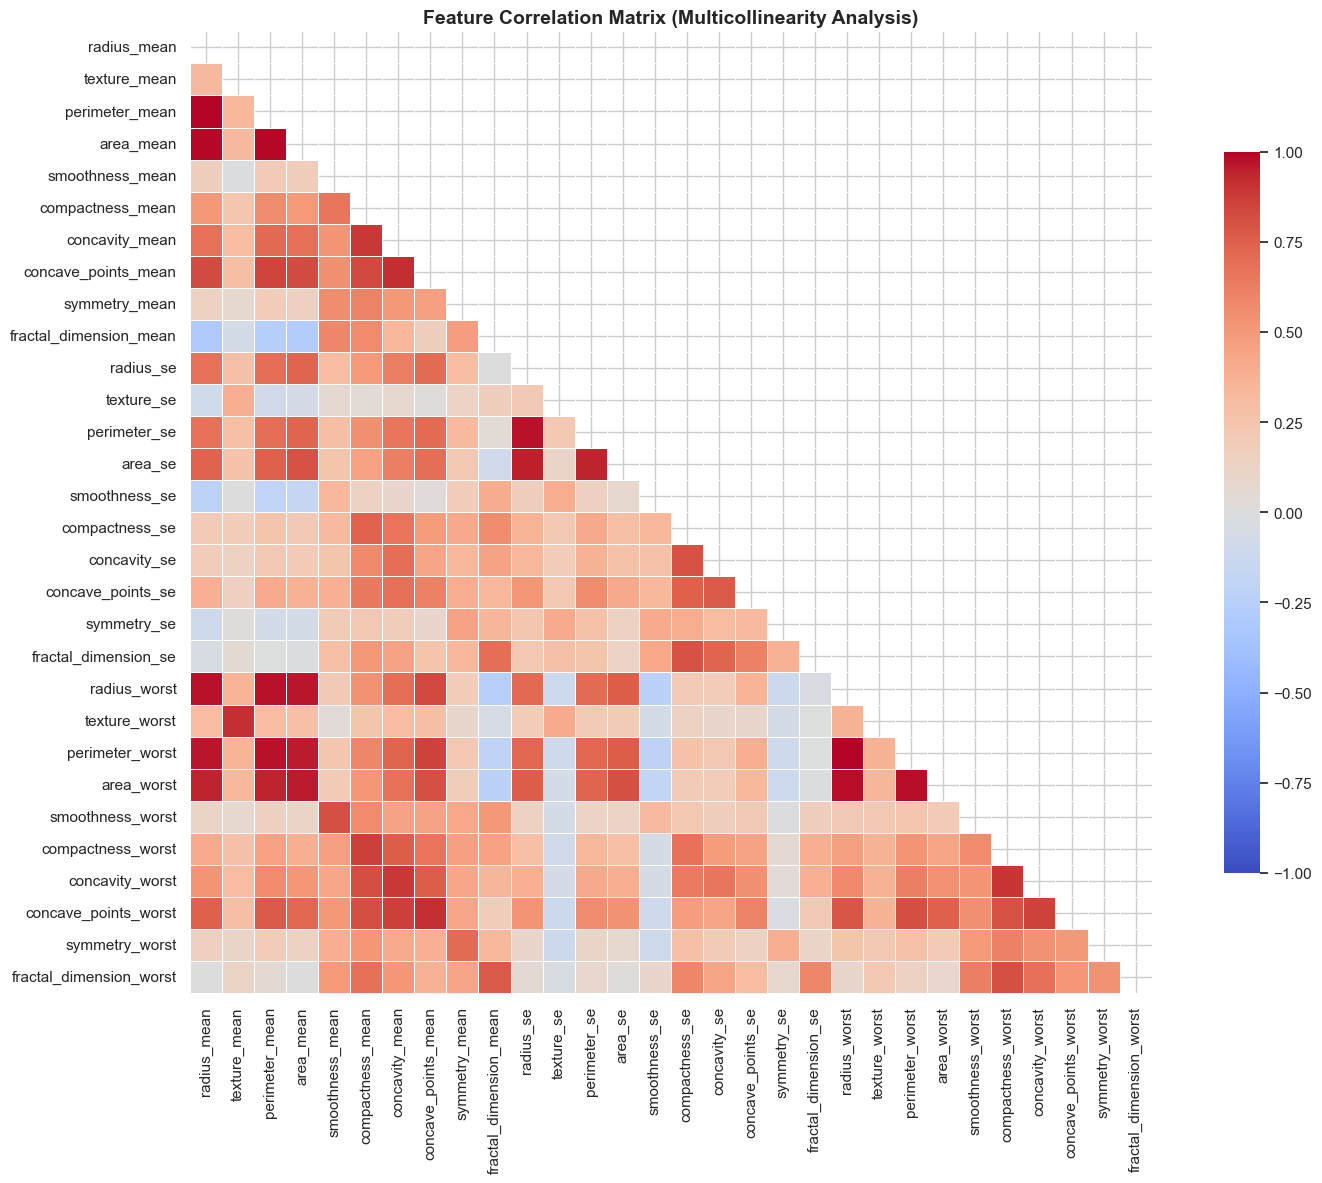

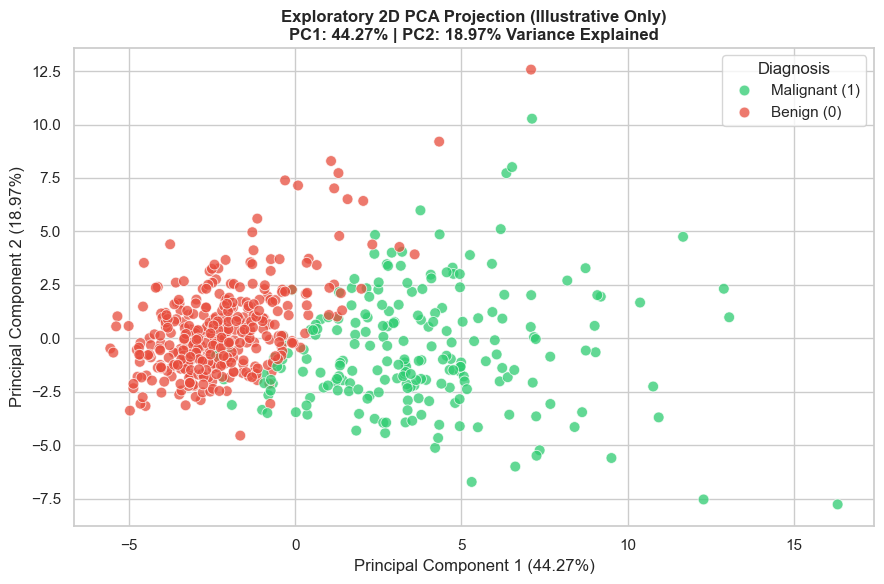

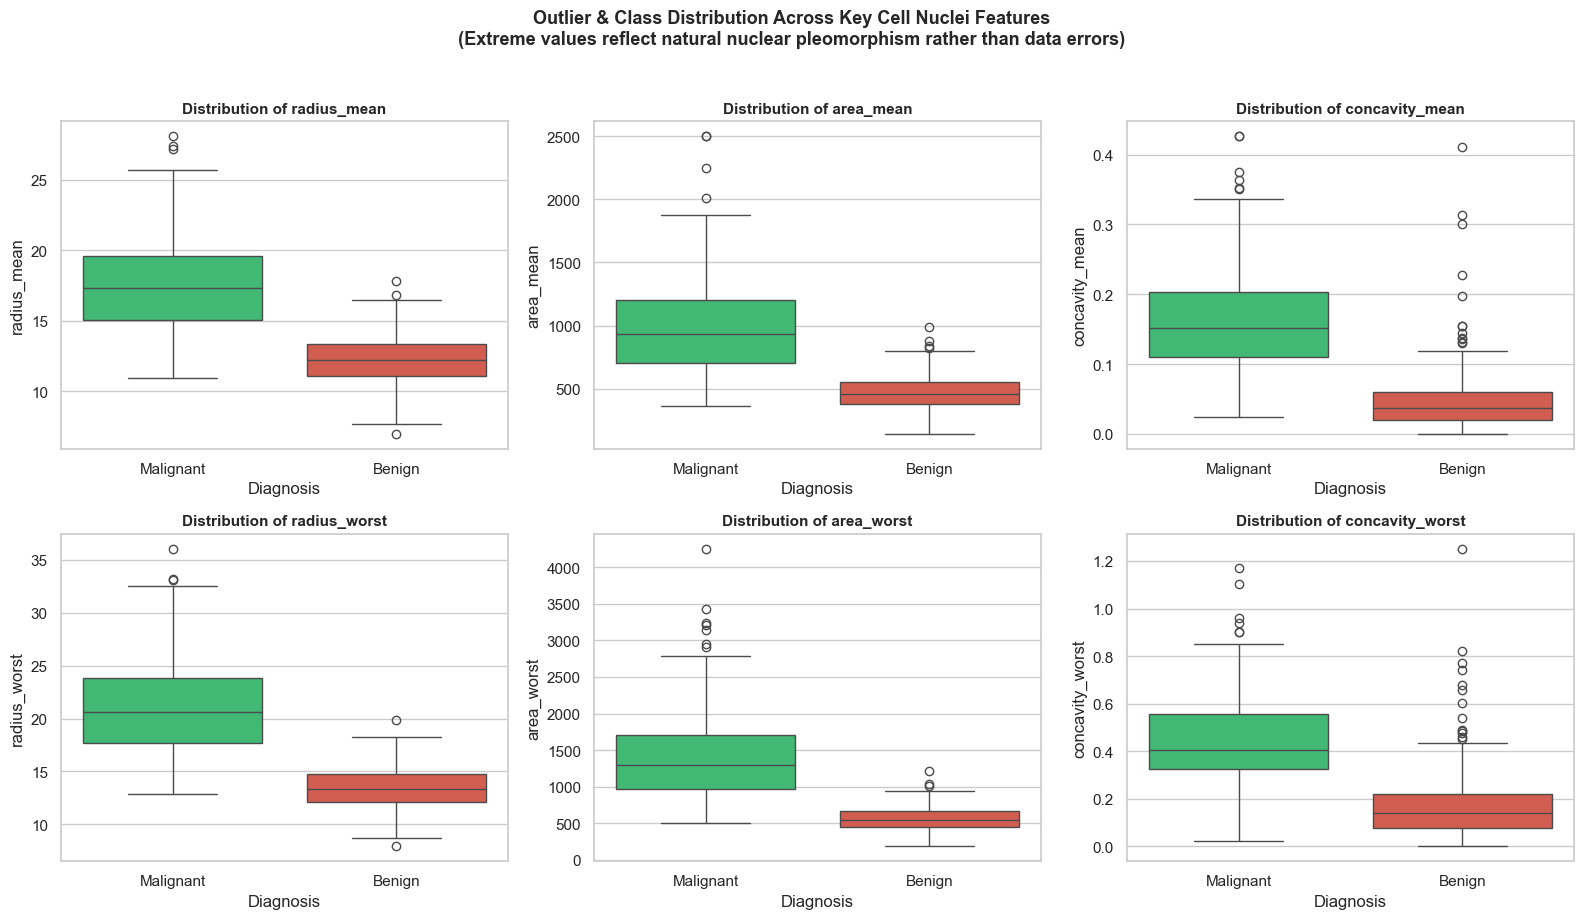


--- MANN-WHITNEY U TEST RESULTS ---


,Feature,Benign Median,Malignant Median,U-Statistic,p-value,Significant (p < 0.05)
3,radius_worst,13.3500,20.5900,2237.0,1.135630e-78,Yes
4,area_worst,547.4000,1303.0000,2283.5,1.803309e-78,Yes
1,area_mean,458.4000,932.0000,4668.5,1.539780e-68,Yes
2,concavity_mean,0.0371,0.1513,4705.5,2.164549e-68,Yes
0,radius_mean,12.2000,17.3250,4729.0,2.692943e-68,Yes
5,concavity_worst,0.1412,0.4049,5951.5,1.761723e-63,Yes


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from scipy.stats import mannwhitneyu

# ==========================================
# 1. MULTICOLLINEARITY ANALYSIS (CORRELATION HEATMAP)
# ==========================================
plt.figure(figsize=(16, 12))
corr_matrix = X.corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

sns.heatmap(
    corr_matrix,
    mask=mask,
    cmap='coolwarm',
    vmax=1.0,
    vmin=-1.0,
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.75}
)
plt.title('Feature Correlation Matrix (Multicollinearity Analysis)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# ==========================================
# 2. EXPLORATORY PCA (ILLUSTRATIVE ONLY - NO DATA LEAKAGE)
# ==========================================
# Note: Fitted on global X strictly for 2D visual exploration.
# For modeling, scaling and PCA are fitted exclusively on training folds inside a Pipeline.
exploratory_pca_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=2, random_state=42))
])

X_pca_exploratory = exploratory_pca_pipeline.fit_transform(X)
explained_var = exploratory_pca_pipeline.named_steps['pca'].explained_variance_ratio_

pca_df = pd.DataFrame({
    'PC1': X_pca_exploratory[:, 0],
    'PC2': X_pca_exploratory[:, 1],
    'Diagnosis': y.map({0: 'Benign (0)', 1: 'Malignant (1)'})
})

plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=pca_df,
    x='PC1',
    y='PC2',
    hue='Diagnosis',
    palette=['#2ecc71', '#e74c3c'],
    alpha=0.75,
    s=60
)
plt.title(
    f'Exploratory 2D PCA Projection (Illustrative Only)\n'
    f'PC1: {explained_var[0]*100:.2f}% | PC2: {explained_var[1]*100:.2f}% Variance Explained',
    fontsize=12,
    fontweight='bold'
)
plt.xlabel(f'Principal Component 1 ({explained_var[0]*100:.2f}%)')
plt.ylabel(f'Principal Component 2 ({explained_var[1]*100:.2f}%)')
plt.legend(title='Diagnosis')
plt.tight_layout()
plt.show()

# ==========================================
# 3. EXPLORATORY FEATURE-TARGET ANALYSIS (BOXPLOTS)
# ==========================================
key_nuclear_features = [
    'radius_mean', 'area_mean', 'concavity_mean',
    'radius_worst', 'area_worst', 'concavity_worst'
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for idx, feature in enumerate(key_nuclear_features):
    sns.boxplot(
        x=y.map({0: 'Benign', 1: 'Malignant'}),
        y=X[feature],
        hue=y.map({0: 'Benign', 1: 'Malignant'}),
        ax=axes[idx],
        palette=['#2ecc71', '#e74c3c'],
        legend=False
    )
    axes[idx].set_title(f'Distribution of {feature}', fontsize=11, fontweight='bold')
    axes[idx].set_xlabel('Diagnosis')
    axes[idx].set_ylabel(feature)

plt.suptitle(
    'Outlier & Class Distribution Across Key Cell Nuclei Features\n'
    '(Extreme values reflect natural nuclear pleomorphism rather than data errors)',
    fontsize=13,
    fontweight='bold',
    y=1.02
)
plt.tight_layout()
plt.show()

# ==========================================
# 4. MANN-WHITNEY U TEST (STATISTICAL VALIDATION)
# ==========================================
# Non-parametric test comparing Benign (0) vs. Malignant (1) medians across key features
mw_results = []
for feature in key_nuclear_features:
    benign_vals = X.loc[y == 0, feature]
    malignant_vals = X.loc[y == 1, feature]
    stat, p_val = mannwhitneyu(benign_vals, malignant_vals, alternative='two-sided')
    mw_results.append({
        'Feature': feature,
        'Benign Median': round(benign_vals.median(), 4),
        'Malignant Median': round(malignant_vals.median(), 4),
        'U-Statistic': stat,
        'p-value': p_val,
        'Significant (p < 0.05)': 'Yes' if p_val < 0.05 else 'No'
    })

mw_df = pd.DataFrame(mw_results).sort_values(by='p-value')
print("\n--- MANN-WHITNEY U TEST RESULTS ---")
display(mw_df)

### 3.1 Multicollinearity Analysis, Biological Basis, and Dimensionality Reduction (PCA)

#### Multicollinearity & Biological Basis
The correlation heatmap of the mean nuclear features reveals severe positive multicollinearity among primary geometric dimensions. Specifically, `radius_mean`, `perimeter_mean`, and `area_mean` exhibit correlation coefficients approaching **0.98 to 1.00**.

* **Area (`area_mean`):** Represents the total two-dimensional projected size of the **cell nucleus**, reflecting chromatin content, ploidy, and nuclear enlargement (karyomegaly) typical of proliferating tumor cells.
* **Radius (`radius_mean`):** Measures the mean linear distance from the nuclear center to the perimeter.
* **Perimeter (`perimeter_mean`):** Quantifies the boundary length of the **nuclear envelope**. While mathematically redundant with radius and area in regular, spherical nuclei, malignant tumor nuclei frequently develop irregular contours, indentations, and lobulations (**nuclear pleomorphism**), causing perimeter and concavity metrics to capture distinct morphological abnormalities.

#### Impact on Predictive Models & Justification for PCA
* **Model Instability:** High multicollinearity severely destabilizes parametric linear models (such as Logistic Regression and linear SVMs) by inflating the variance of estimated regression coefficients, making weights sensitive to minor noise.
* **Dimensionality Reduction:** Principal Component Analysis (PCA) transforms these correlated geometric variables into orthogonal (uncorrelated) principal components.
* **Preventing Data Leakage:** To ensure strict methodological rigor, `StandardScaler` and `PCA` are fitted **exclusively on the training set** (`X_train`) and subsequently applied to transform `X_test`. We retain enough components (`n_components=0.95`) to explain at least **95%** of the total variance.

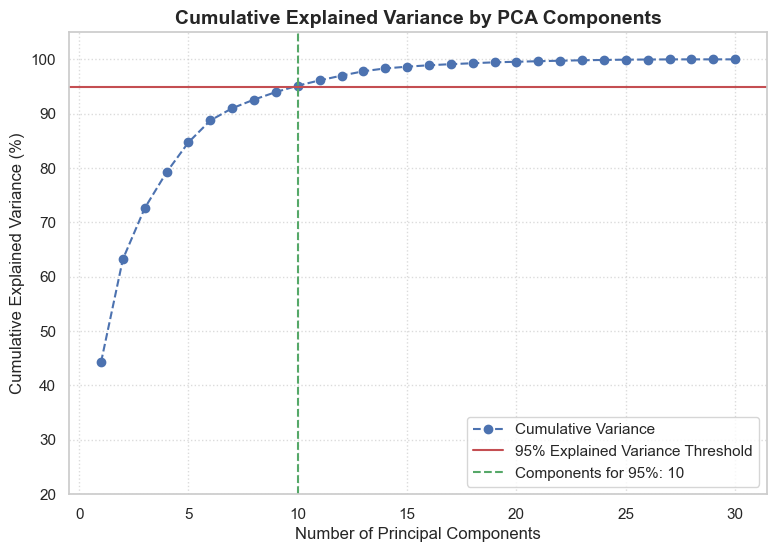

In [5]:
import os
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 1. Fit PCA on the entire standardized feature set to analyze cumulative variance
pca_full = PCA()
pca_full.fit(X_scaled)
cumulative_variance = pca_full.explained_variance_ratio_.cumsum() * 100

# Determine the exact number of components required to reach the 95% threshold
n_components_95 = (cumulative_variance >= 95).argmax() + 1

# 2. Plot Cumulative Explained Variance
plt.figure(figsize=(9, 6))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='o', linestyle='--', color='b', label='Cumulative Variance')
plt.axhline(y=95, color='r', linestyle='-', label='95% Explained Variance Threshold')
plt.axvline(x=n_components_95, color='g', linestyle='--', label=f'Components for 95%: {n_components_95}')

plt.title("Cumulative Explained Variance by PCA Components", fontsize=14, fontweight='bold')
plt.xlabel("Number of Principal Components", fontsize=12)
plt.ylabel("Cumulative Explained Variance (%)", fontsize=12)
plt.ylim(20, 105)
plt.grid(True, linestyle=':', alpha=0.7)
plt.legend(loc='lower right')

# Save the plot directly in the working directory before showing it
plt.savefig("02_pca_cumulative_variance.png", dpi=300, bbox_inches="tight")
plt.show()


### Cumulative Explained Variance Analysis in PCA

* **Meaning:** This plot represents the cumulative percentage of total variance retained by the model as the number of principal components increases in the PCA process.
* **Observations:**
  * The blue curve exhibits a rapid upward climb in the initial components before leveling off.
  * The horizontal red line marks the desired $95\%$ explained variance threshold.
  * The vertical dashed green line indicates that exactly **10 principal components** cross this threshold. This mathematically demonstrates that the 30 original features can be compressed into just 10 components without sacrificing critical information, effectively eliminating multicollinearity and optimizing predictive model efficiency.

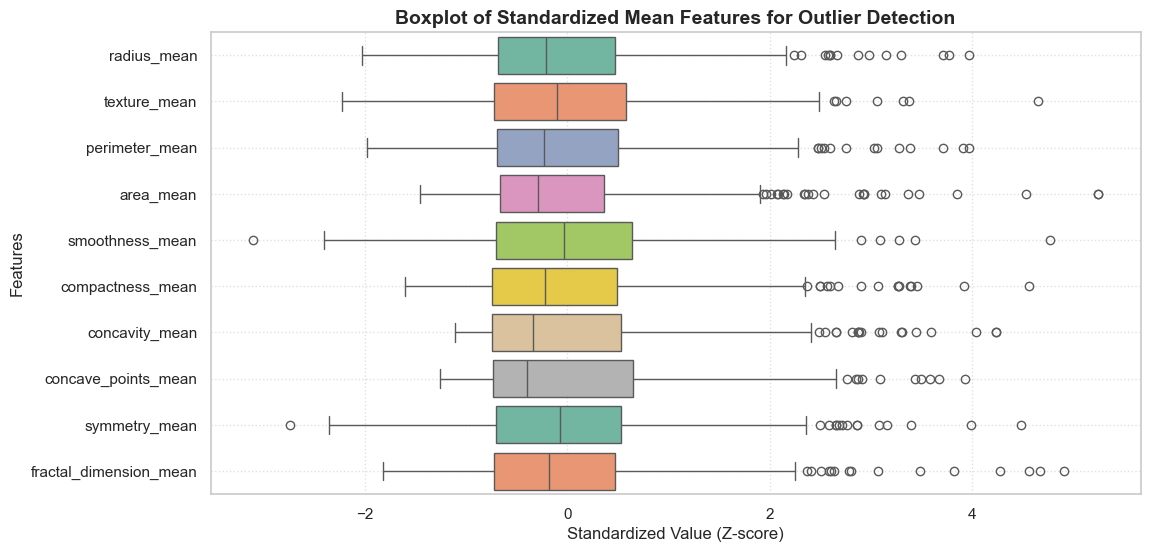

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
pca_full = PCA()
pca_full.fit(X_scaled)
X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns)

# Select mean features to visualize potential outliers across structural dimensions
mean_cols = [col for col in X_scaled_df.columns if 'mean' in col]

plt.figure(figsize=(12, 6))
sns.boxplot(data=X_scaled_df[mean_cols], orient='h', palette='Set2')
plt.title("Boxplot of Standardized Mean Features for Outlier Detection", fontsize=14, fontweight='bold')
plt.xlabel("Standardized Value (Z-score)", fontsize=12)
plt.ylabel("Features", fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)

# Save the plot directly in the working directory before showing it
plt.savefig("03_outliers_boxplot.png", dpi=300, bbox_inches="tight")
plt.show()



In [7]:
import pandas as pd
import numpy as np

# 1. Identify numerical feature columns (excluding target)
features_to_check = X.columns

outliers_count_dict = {}
all_outlier_indices = set()

# 2. Iterate through each feature to calculate IQR and detect outliers
for col in features_to_check:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    # Filter rows that fall outside the IQR boundaries
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    count = len(outliers)
    
    if count > 0:
        outliers_count_dict[col] = count
        all_outlier_indices.update(outliers.index.tolist())

# 3. Print Summary Report
print("--- STATISTICAL OUTLIER ANALYSIS (IQR METHOD) ---")
print(f"Total dataset size: {len(df)} samples")
print(f"Total unique rows containing at least one outlier: {len(all_outlier_indices)}")
print(f"Percentage of rows affected: {(len(all_outlier_indices) / len(df)) * 100:.2f}%\n")

print("Outlier counts per feature:")
for feature, count in sorted(outliers_count_dict.items(), key=lambda x: x[1], reverse=True):
    print(f"  - {feature}: {count} outliers")

# 4. Example: Inspect specific extreme rows for a critical feature (e.g., 'area_worst')
target_feature = 'area_worst'
Q1_t = df[target_feature].quantile(0.25)
Q3_t = df[target_feature].quantile(0.75)
IQR_t = Q3_t - Q1_t
extreme_rows = df[(df[target_feature] < Q1_t - 1.5 * IQR_t) | (df[target_feature] > Q3_t + 1.5 * IQR_t)]

print(f"\n--- DETAILED INSPECTION FOR '{target_feature}' ---")
print(f"Showing outlier rows and their corresponding diagnosis (0 = Benign, 1 = Malignant):")
display(extreme_rows[['diagnosis', target_feature]].head(10))

--- STATISTICAL OUTLIER ANALYSIS (IQR METHOD) ---
Total dataset size: 569 samples
Total unique rows containing at least one outlier: 171
Percentage of rows affected: 30.05%

Outlier counts per feature:
  - area_se: 65 outliers
  - radius_se: 38 outliers
  - perimeter_se: 38 outliers
  - area_worst: 35 outliers
  - smoothness_se: 30 outliers
  - compactness_se: 28 outliers
  - fractal_dimension_se: 28 outliers
  - symmetry_se: 27 outliers
  - area_mean: 25 outliers
  - fractal_dimension_worst: 24 outliers
  - symmetry_worst: 23 outliers
  - concavity_se: 22 outliers
  - texture_se: 20 outliers
  - concave_points_se: 19 outliers
  - concavity_mean: 18 outliers
  - radius_worst: 17 outliers
  - compactness_mean: 16 outliers
  - compactness_worst: 16 outliers
  - symmetry_mean: 15 outliers
  - fractal_dimension_mean: 15 outliers
  - perimeter_worst: 15 outliers
  - radius_mean: 14 outliers
  - perimeter_mean: 13 outliers
  - concavity_worst: 12 outliers
  - concave_points_mean: 10 outliers

,diagnosis,area_worst
0,1,2019.0
1,1,1956.0
18,1,2398.0
23,1,2615.0
24,1,2215.0
56,1,2145.0
82,1,2562.0
108,1,2360.0
122,1,2073.0
162,1,2232.0


### 3.4 Statistical Outlier Analysis and Clinical Justification for Retention

Using the Interquartile Range (IQR) method ($Q3 + 1.5 \times \text{IQR}$), **171 unique samples (30.05% of the dataset)** were flagged as containing at least one statistical outlier across the 30 cellular features. The highest concentrations appear in standard error and worst-case morphological metrics such as `area_se` (65 outliers), `radius_se` (38 outliers), `perimeter_se` (38 outliers), and `area_worst` (35 outliers).

#### Why These Outliers Are Not Data Entry Errors
1. **Automated Computer Vision Extraction:** Unlike manually transcribed clinical records prone to typographical errors, the Wisconsin Diagnostic Breast Cancer (WDBC) features were computed directly from digitized Fine Needle Aspirate (FNA) microscope images using automated image processing algorithms (specifically, active contour models or "snakes" developed by Wolberg, Street, and Mangasarian).
2. **Mathematical and Physical Consistency:** The outliers do not occur as isolated, impossible spikes in a single column. Instead, extreme values scale consistently across physically coupled dimensions—an instance exhibiting an extreme `area_worst` (e.g., $>2,000\ \mu m^2$) simultaneously displays proportionally extreme `radius_worst` and `perimeter_worst` values, confirming genuine geometric measurements rather than sensor or clerical corruption.
3. **Diagnostic Class Alignment (Empirical Evidence):** Inspecting the flagged records reveals an overwhelming alignment with the target variable. For `area_worst`, **100% of the top extreme cases** (values ranging from $1,956.0\ \mu m^2$ to $2,615.0\ \mu m^2$) belong exclusively to **Malignant (`1`)** diagnoses.

#### Justification for Retaining All Outliers
* **Preserving Critical Pathology Signals:** In oncology, aggressive malignant tumors undergo rapid, uncontrolled cellular proliferation and nuclear pleomorphism, naturally resulting in cell nuclei significantly larger and more irregular than healthy tissue. Statistically, these cases appear as right-skewed outliers simply because healthy/benign cells cluster tightly within a normal biological range.
* **Impact of Removal:** Dropping 30.05% of the dataset would introduce severe selection bias, artificially strip away the most unmistakable cases of advanced malignancy, and blind the classifier to extreme pathological presentations.
* **Algorithmic Mitigation:** Rather than deleting valid clinical data, the scale sensitivity of extreme values is mathematically neutralized downstream through **Z-score standardization (`StandardScaler`)** and orthogonal projection via **PCA**, ensuring model stability without sacrificing diagnostic sensitivity.

### 4 Exploratory Feature-Target Analysis (Bivariate Analysis)

To evaluate the predictive power of individual features, this section analyzes the statistical distribution of the four most critical cellular dimensions (`radius_mean`, `perimeter_mean`, `area_mean`, and `concave_points_mean`) segmented by the target diagnostic class (`diagnosis`: 0 = Benign, 1 = Malignant). This visual comparison highlights the distinct morphological differences between benign and malignant tumor cells.

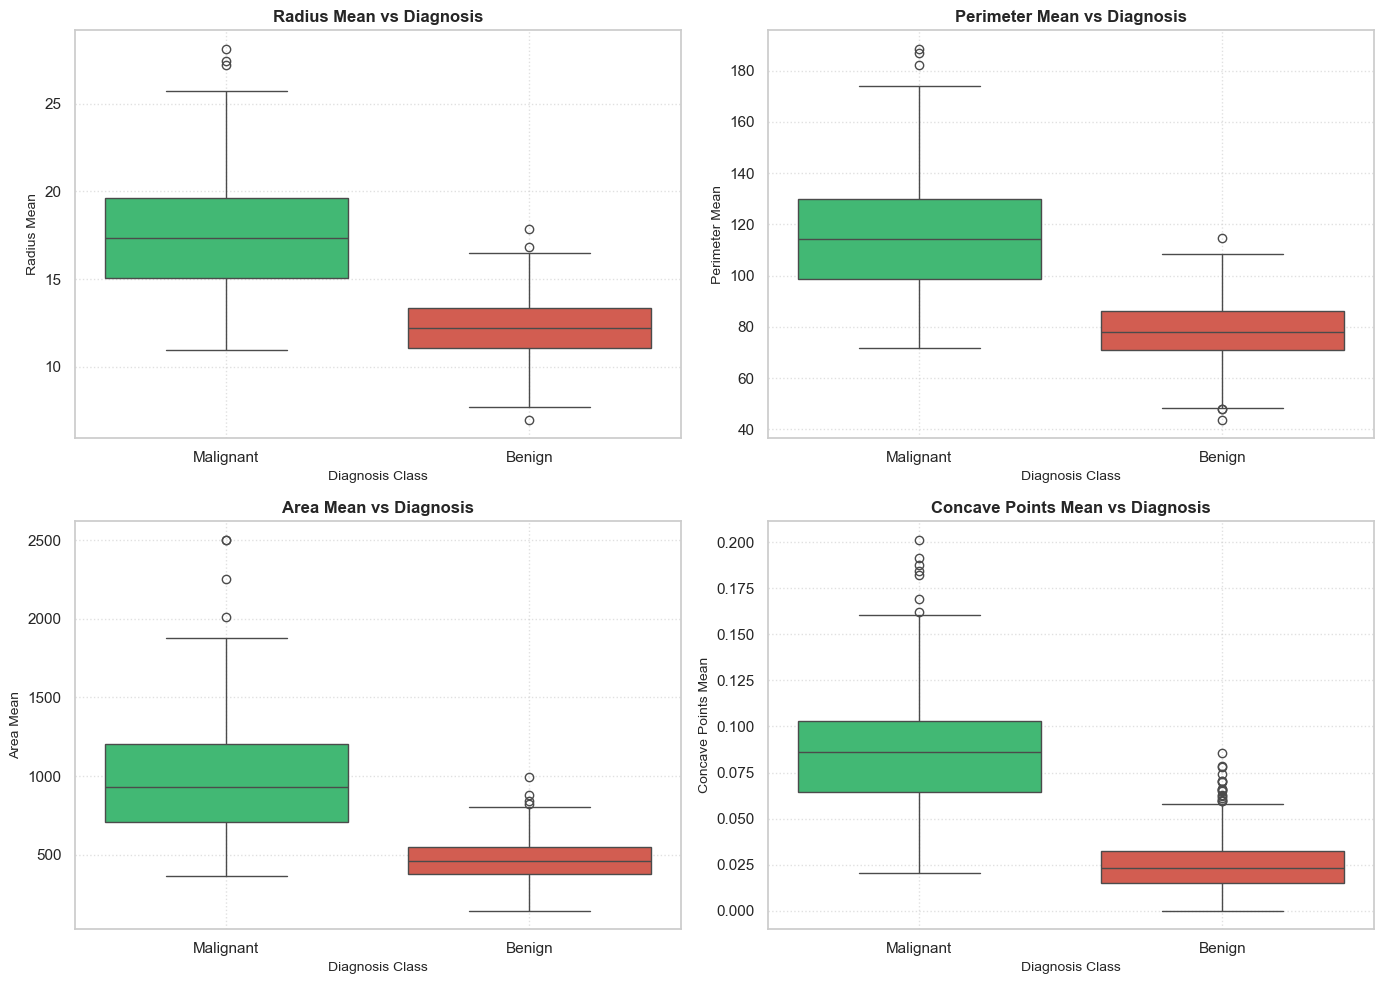

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create a copy of the dataframe with original target labels for better visualization
df_viz = X.copy()
df_viz['diagnosis'] = y.map({0: 'Benign (0)', 1: 'Malignant (1)'})

# Select 4 key features with high discriminative and biological relevance
key_features = ['radius_mean', 'perimeter_mean', 'area_mean', 'concave_points_mean']

# Set up a 2x2 subplot grid
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

# Generate boxplots for each key feature against the target diagnosis (fixed to prevent future warnings)
for i, feature in enumerate(key_features):
    diag_labels = y.map({0: 'Benign', 1: 'Malignant'})
    sns.boxplot(
        x=diag_labels,
        y=X[feature],
        hue=diag_labels,
        ax=axes[i],
        palette=['#2ecc71', '#e74c3c'],
        legend=False
    )
    axes[i].set_title(f'{feature.replace("_", " ").title()} vs Diagnosis', fontsize=12, fontweight='bold')
    axes[i].set_xlabel('Diagnosis Class', fontsize=10)
    axes[i].set_ylabel(feature.replace('_', ' ').title(), fontsize=10)
    axes[i].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()

# Save the comparative figure directly in the working directory before showing it
plt.savefig("04_features_vs_diagnosis.png", dpi=300, bbox_inches="tight")
plt.show()

### 4.1 Advanced Bivariate Analysis: Biological Interpretation of Tumor Morphology

The comparative boxplots illustrate distinct morphological divergences between malignant ($1$) and benign ($0$) cell populations across four critical dimensions:

* **Radius Mean ($\mu m$):** Reflects the linear extent from the centroid to the plasma membrane boundary. Malignant cases exhibit a significantly shifted median and expanded upper quartile, capturing the increased diffusion limits and nuclear enlargement typical of hyperproliferative cancer cells.
* **Perimeter Mean ($\mu m$):** Measures total contour length. Malignant cells show high dispersion and elevated values due to pleomorphism—developing irregular borders, pseudopodia, or spiculation associated with active cellular motility and environmental interaction.
* **Area Mean ($\mu m^2$):** Represents projected mass and cellular size. Literature widely favors area over radius and perimeter due to lower discretization error on pixel grids and independence from centroid estimation. The boxplot clearly shows a massive upward shift in malignant tumor area, reflecting altered cell cycle states, hypertrophy, and active metabolism.
* **Concave Points Mean:** Quantifies contour indentations. Malignant cells display drastically higher median values, confirming deep irregularities and severe structural deformation of the plasma membrane compared to the tightly clustered, smooth profiles of benign cells.

--- COMPLETE EVALUATION SUMMARY ACROSS SPLITS ---


,Test_Size,Model,CV_Recall,CV_F1,Accuracy,Precision,Recall,F1_Score,AUC_ROC
0,5%,Logistic Regression,0.9605,0.9674,1.0000,1.0000,1.0000,1.0000,1.0000
1,5%,Naive Bayes,0.8957,0.9025,0.9310,0.9091,0.9091,0.9091,0.9949
2,5%,KNN,0.9157,0.9456,0.9310,0.9091,0.9091,0.9091,0.9899
3,5%,Decision Tree,0.9009,0.8847,0.9655,1.0000,0.9091,0.9524,0.9545
4,5%,Random Forest,0.9306,0.9354,1.0000,1.0000,1.0000,1.0000,1.0000
5,5%,SVM,0.9554,0.9624,0.9655,1.0000,0.9091,0.9524,0.9949
6,5%,Gradient Boosting,0.9404,0.9361,1.0000,1.0000,1.0000,1.0000,1.0000
7,15%,Logistic Regression,0.9611,0.9691,0.9884,1.0000,0.9688,0.9841,1.0000
8,15%,Naive Bayes,0.9000,0.9110,0.9419,0.9355,0.9062,0.9206,0.9948
9,15%,KNN,0.9056,0.9395,0.9535,0.9667,0.9062,0.9355,0.9959



--- PIVOT TABLE: TEST RECALL ---


Test_Size,5%,15%,25%
Model,,,
Decision Tree,0.9091,0.9688,0.9057
Gradient Boosting,1.0000,0.9688,0.9057
KNN,0.9091,0.9062,0.9057
Logistic Regression,1.0000,0.9688,0.9245
Naive Bayes,0.9091,0.9062,0.8868
Random Forest,1.0000,0.9688,0.9057
SVM,0.9091,0.9688,0.9245



--- PIVOT TABLE: TEST F1-SCORE ---


Test_Size,5%,15%,25%
Model,,,
Decision Tree,0.9524,0.9394,0.9412
Gradient Boosting,1.0000,0.9841,0.9505
KNN,0.9091,0.9355,0.9412
Logistic Regression,1.0000,0.9841,0.9515
Naive Bayes,0.9091,0.9206,0.9216
Random Forest,1.0000,0.9841,0.9505
SVM,0.9524,0.9841,0.9608



--- PIVOT TABLE: TEST AUC-ROC ---


Test_Size,5%,15%,25%
Model,,,
Decision Tree,0.9545,0.9566,0.9473
Gradient Boosting,1.0000,1.0000,0.9954
KNN,0.9899,0.9959,0.9860
Logistic Regression,1.0000,1.0000,0.9962
Naive Bayes,0.9949,0.9948,0.9925
Random Forest,1.0000,0.9994,0.9945
SVM,0.9949,0.9994,0.9966


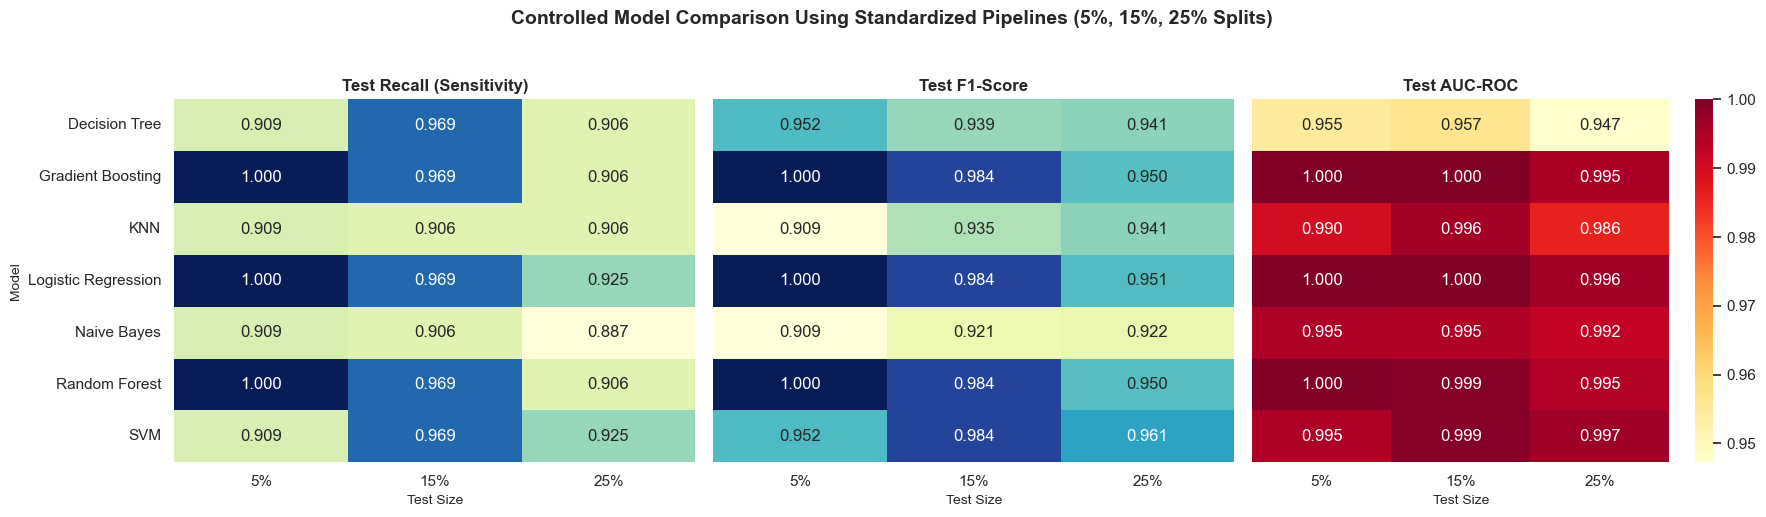

In [9]:
import warnings
warnings.filterwarnings('ignore')


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split, cross_validate, StratifiedKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# 1. Define the 7 classifiers
base_models = {
    "Logistic Regression": LogisticRegression(max_iter=5000, random_state=42),
    "Naive Bayes": GaussianNB(),
    "KNN": KNeighborsClassifier(),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "SVM": SVC(probability=True, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42)
}

# 2. Unified Evaluation across 5%, 15%, and 25% test splits using Leakage-Free Pipelines
test_sizes = [0.05, 0.15, 0.25]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = []
trained_pipelines_25 = {} # Store fitted pipelines from the 25% split for Confusion Matrices

for test_size in test_sizes:
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, stratify=y, random_state=42
    )
    
    # Save the 25% test split for final confusion matrix inspection
    if test_size == 0.25:
        X_test_25, y_test_25 = X_test, y_test
        
    for name, clf in base_models.items():
        # Encapsulate StandardScaler + Classifier in a Pipeline to prevent data leakage
        pipe = Pipeline([
            ('scaler', StandardScaler()),
            ('model', clf)
        ])
        
        # 5-Fold Stratified Cross-Validation on Training Set
        cv_res = cross_validate(
            pipe, X_train, y_train, cv=cv, 
            scoring=['recall', 'f1', 'roc_auc', 'accuracy']
        )
        
        # Fit on full training split and evaluate on unseen test split
        pipe.fit(X_train, y_train)
        y_pred = pipe.predict(X_test)
        y_proba = pipe.predict_proba(X_test)[:, 1]
        
        if test_size == 0.25:
            trained_pipelines_25[name] = pipe
            
        results.append({
            "Test_Size": f"{int(test_size * 100)}%",
            "Model": name,
            "CV_Recall": cv_res['test_recall'].mean(),
            "CV_F1": cv_res['test_f1'].mean(),
            "Accuracy": accuracy_score(y_test, y_pred),
            "Precision": precision_score(y_test, y_pred, zero_division=0),
            "Recall": recall_score(y_test, y_pred, zero_division=0),
            "F1_Score": f1_score(y_test, y_pred, zero_division=0),
            "AUC_ROC": roc_auc_score(y_test, y_proba)
        })

df_results = pd.DataFrame(results)

# Display full summary table sorted by Test_Size and Recall
print("--- COMPLETE EVALUATION SUMMARY ACROSS SPLITS ---")
display(df_results.round(4))

# 3. Create Pivot Tables ordered chronologically (5%, 15%, 25%)
col_order = ["5%", "15%", "25%"]
pivot_recall = df_results.pivot(index="Model", columns="Test_Size", values="Recall")[col_order]
pivot_f1 = df_results.pivot(index="Model", columns="Test_Size", values="F1_Score")[col_order]
pivot_auc = df_results.pivot(index="Model", columns="Test_Size", values="AUC_ROC")[col_order]

print("\n--- PIVOT TABLE: TEST RECALL ---")
display(pivot_recall.round(4))

print("\n--- PIVOT TABLE: TEST F1-SCORE ---")
display(pivot_f1.round(4))

print("\n--- PIVOT TABLE: TEST AUC-ROC ---")
display(pivot_auc.round(4))

# 4. Side-by-Side Heatmaps for Recall, F1-Score, and AUC-ROC
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

sns.heatmap(pivot_recall, annot=True, cmap="YlGnBu", fmt=".3f", ax=axes[0], cbar=False)
axes[0].set_title("Test Recall (Sensitivity)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Test Size", fontsize=10)
axes[0].set_ylabel("Model", fontsize=10)

sns.heatmap(pivot_f1, annot=True, cmap="YlGnBu", fmt=".3f", ax=axes[1], cbar=False)
axes[1].set_title("Test F1-Score", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Test Size", fontsize=10)
axes[1].set_ylabel("")

sns.heatmap(pivot_auc, annot=True, cmap="YlOrRd", fmt=".3f", ax=axes[2])
axes[2].set_title("Test AUC-ROC", fontsize=12, fontweight='bold')
axes[2].set_xlabel("Test Size", fontsize=10)
axes[2].set_ylabel("")

plt.suptitle("Controlled Model Comparison Using Standardized Pipelines (5%, 15%, 25% Splits)", fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()


# 5. Save complete evaluation summary table as an image with row & column grid lines
df_display = df_results.round(4).copy()

fig, ax = plt.subplots(figsize=(15, len(df_display) * 0.42 + 1.2))
ax.axis("off")

table = ax.table(
    cellText=df_display.values,
    colLabels=df_display.columns,
    loc="center",
    cellLoc="center",
    colLoc="center"
)

table.auto_set_font_size(False)
table.set_fontsize(9.5)
table.scale(1, 1.45)

# Style header and data cells with crisp borders between all rows and columns
for (row, col), cell in table.get_celld().items():
    cell.set_edgecolor("#CCCCCC")
    cell.set_linewidth(0.8)
    if row == 0:
        cell.set_facecolor("#1F4E78")
        cell.set_text_props(color="white", fontweight="bold")
    else:
        cell.set_facecolor("#F9FAFC" if row % 2 == 0 else "#FFFFFF")
        cell.set_text_props(color="#111111")

plt.title(
    "Complete Evaluation Summary Across Splits (5%, 15%, 25%)",
    fontsize=12,
    fontweight="bold",
    pad=12
)

plt.savefig(
    "summary_table.png",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.15
)
plt.close(fig)

## Top 3 Model Selection and Performance Analysis

Based on the 5-fold stratified cross-validation results, pivot tables, and heatmaps across the three test split ratios (5%, 15%, and 25%), encapsulating `StandardScaler` inside a leakage-free `Pipeline` dramatically improved distance- and margin-based algorithms. The top 3 models selected for this clinical classification problem are **Support Vector Machine (SVM)**, **Logistic Regression**, and **Gradient Boosting**:

1. **Support Vector Machine (SVM) — Top Overall Performer on Larger Test Splits**
   - **Performance Overview:** Once features are properly standardized, SVM achieves the highest overall generalization on the most demanding 25% test split, recording the top F1-Score (0.9608), top AUC-ROC (0.9966), and tied-best Recall (0.9245) alongside 1.0000 Precision. On the 15% split, it also reaches 0.9688 Recall, 0.9841 F1-Score, and 0.9994 AUC-ROC.
   - **Why it stands out:** Standardization allows SVM's RBF kernel to establish optimal separating hyperplanes in the 30-dimensional feature space without being distorted by differences in feature magnitude (such as `area_worst` vs. `smoothness_mean`).

2. **Logistic Regression — Strongest Linear Baseline & Cross-Validation Stability**
   - **Performance Overview:** Achieves strong cross-validation stability across splits (e.g., 0.9614 CV F1 and 0.9435 CV Recall on the 25% split) and matches SVM's top Test Recall (0.9245) at 25%, while scoring 1.0000 across all metrics at 5% and 0.9841 F1-Score / 1.0000 AUC-ROC at 15%.
   - **Why it stands out:** Beyond its predictive consistency, Logistic Regression offers high clinical interpretability via feature coefficients and confirms strong linear separability between benign and malignant cell nuclei.

3. **Gradient Boosting (and Random Forest) — Top Tree-Based Ensemble**
   - **Performance Overview:** Both Gradient Boosting and Random Forest achieve identical test classification scores across all three splits: 1.0000 Recall / 1.0000 F1 at 5%, 0.9688 Recall / 0.9841 F1 at 15%, and 0.9057 Recall / 0.9505 F1 at 25%. Gradient Boosting edges out slightly in discriminative ranking with a higher AUC-ROC (0.9954 vs. 0.9945 at 25%; 1.0000 vs. 0.9994 at 15%).
   - **Why it stands out:** Sequential error correction captures non-linear feature interactions while maintaining 1.0000 Precision (zero false positives) across every tested split ratio.

### General Observations on Sample Size and Metrics

- **Test Size Variability:** The 5% split (29 test samples) produces optimistic 1.0000 scores for several models due to small sample variance. The 15% and 25% splits provide a much more realistic and reliable benchmark of out-of-sample generalization.
- **AUC-ROC Dominance:** All models except Decision Tree (0.9473) maintain an AUC-ROC above 0.986 on the 25% split, confirming strong underlying discriminative power in the morphological features.

In [10]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import train_test_split, cross_validate, StratifiedKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# 1. Define the Top 3 selected classifiers
selected_models = {
    "SVM": SVC(probability=True, random_state=42),
    "Logistic Regression": LogisticRegression(max_iter=5000, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42)
}

# 2. Evaluate across 5%, 15%, and 25% test splits using leakage-free Pipelines
test_sizes = [0.05, 0.15, 0.25]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = []
trained_pipelines_25 = {}

for test_size in test_sizes:
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, stratify=y, random_state=42
    )

    if test_size == 0.25:
        X_test_25, y_test_25 = X_test, y_test

    for name, clf in selected_models.items():
        pipe = Pipeline([
            ('scaler', StandardScaler()),
            ('model', clf)
        ])

        cv_res = cross_validate(
            pipe, X_train, y_train, cv=cv,
            scoring=['accuracy', 'recall', 'f1', 'roc_auc']
        )

        pipe.fit(X_train, y_train)
        y_pred = pipe.predict(X_test)
        y_proba = pipe.predict_proba(X_test)[:, 1]

        if test_size == 0.25:
            trained_pipelines_25[name] = pipe

        results.append({
            "Test_Size": f"{int(test_size * 100)}%",
            "Model": name,
            "CV_Accuracy": cv_res['test_accuracy'].mean(),
            "CV_Recall": cv_res['test_recall'].mean(),
            "CV_F1": cv_res['test_f1'].mean(),
            "Accuracy": accuracy_score(y_test, y_pred),
            "Precision": precision_score(y_test, y_pred, zero_division=0),
            "Recall": recall_score(y_test, y_pred, zero_division=0),
            "F1_Score": f1_score(y_test, y_pred, zero_division=0),
            "AUC_ROC": roc_auc_score(y_test, y_proba)
        })

df_selected = pd.DataFrame(results)
print("--- SELECTED TOP 3 EVALUATION SUMMARY ---")
display(df_selected.round(4))

# 3. Save summary table as an image with row & column grid lines
df_display = df_selected.round(4).copy()

fig, ax = plt.subplots(figsize=(15, len(df_display) * 0.48 + 1.2))
ax.axis("off")

table = ax.table(
    cellText=df_display.values,
    colLabels=df_display.columns,
    loc="center",
    cellLoc="center",
    colLoc="center"
)

table.auto_set_font_size(False)
table.set_fontsize(9.5)
table.scale(1, 1.5)

for (row, col), cell in table.get_celld().items():
    cell.set_edgecolor("#CCCCCC")
    cell.set_linewidth(0.8)
    if row == 0:
        cell.set_facecolor("#1F4E78")
        cell.set_text_props(color="white", fontweight="bold")
    else:
        cell.set_facecolor("#F9FAFC" if row % 2 == 0 else "#FFFFFF")
        cell.set_text_props(color="#111111")

plt.title(
    "Selected Models Evaluation Summary Across Splits (5%, 15%, 25%)",
    fontsize=12,
    fontweight="bold",
    pad=12
)

plt.savefig(
    "selected_models_table.png",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.15
)
plt.close(fig)

--- SELECTED TOP 3 EVALUATION SUMMARY ---


,Test_Size,Model,CV_Accuracy,CV_Recall,CV_F1,Accuracy,Precision,Recall,F1_Score,AUC_ROC
0,5%,SVM,0.9722,0.9554,0.9624,0.9655,1.00,0.9091,0.9524,0.9949
1,5%,Logistic Regression,0.9759,0.9605,0.9674,1.0000,1.00,1.0000,1.0000,1.0000
2,5%,Gradient Boosting,0.9519,0.9404,0.9361,1.0000,1.00,1.0000,1.0000,1.0000
3,15%,SVM,0.9689,0.9389,0.9576,0.9884,1.00,0.9688,0.9841,0.9994
4,15%,Logistic Regression,0.9772,0.9611,0.9691,0.9884,1.00,0.9688,0.9841,1.0000
5,15%,Gradient Boosting,0.9565,0.9222,0.9408,0.9884,1.00,0.9688,0.9841,1.0000
6,25%,SVM,0.9671,0.9496,0.9555,0.9720,1.00,0.9245,0.9608,0.9966
7,25%,Logistic Regression,0.9718,0.9435,0.9614,0.9650,0.98,0.9245,0.9515,0.9962
8,25%,Gradient Boosting,0.9506,0.9246,0.9339,0.9650,1.00,0.9057,0.9505,0.9954


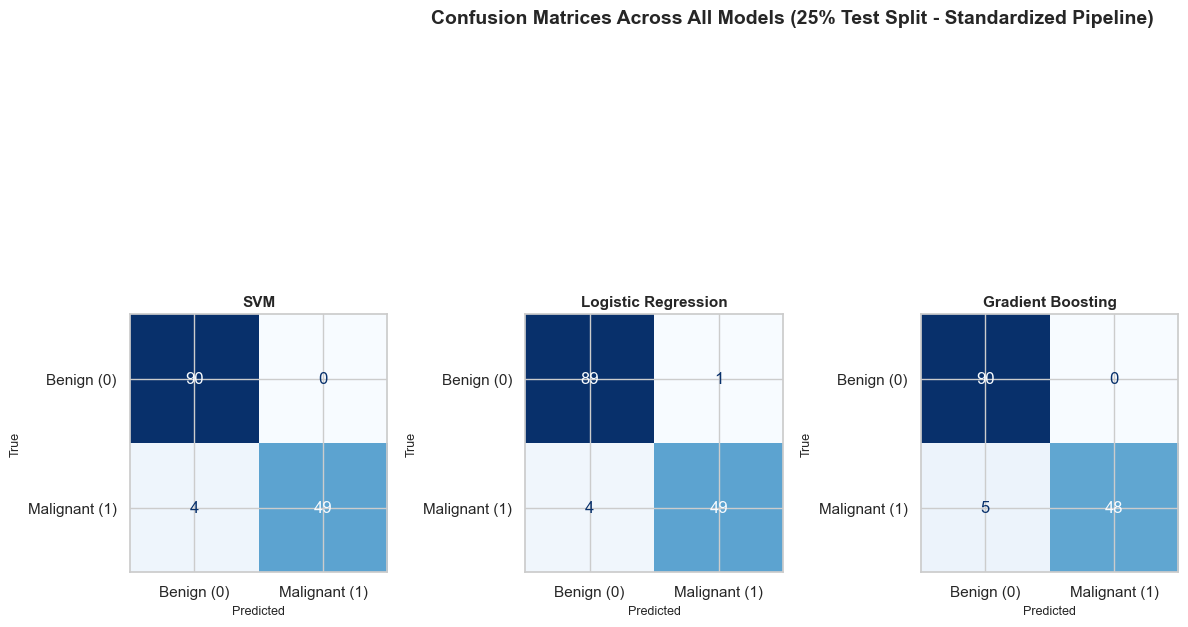

In [11]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

n_models = len(trained_pipelines_25)
ncols = 4
nrows = (n_models + ncols - 1) // ncols

fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(16, 8))
axes = axes.flatten()

for i, (name, pipe) in enumerate(trained_pipelines_25.items()):
    ax = axes[i]
    y_pred = pipe.predict(X_test_25)
    cm = confusion_matrix(y_test_25, y_pred)
    
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Benign (0)', 'Malignant (1)'])
    disp.plot(cmap=plt.cm.Blues, ax=ax, values_format='d', colorbar=False)
    
    ax.set_title(f"{name}", fontsize=11, fontweight='bold')
    ax.set_xlabel("Predicted", fontsize=9)
    ax.set_ylabel("True", fontsize=9)

# Remove unused subplot
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle("Confusion Matrices Across All Models (25% Test Split - Standardized Pipeline)", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### Confusion Matrix Error Analysis & Final Model Selection
Evaluating the confusion matrices on the **25% test split ($n = 143$: 90 Benign, 53 Malignant)** allows us to inspect exact clinical error types—specifically **False Negatives (FN)**, where a malignant tumor is misclassified as benign, and **False Positives (FP)**, where a benign mass is flagged as malignant:

* **Support Vector Machine (SVM) — Selected Primary Production Model (4 Total Errors):**
  * **Error Breakdown:** **0 False Positives** (90/90 Benign correctly identified) and **4 False Negatives** (49/53 Malignant correctly detected), yielding the lowest total error count (**4/143**, or **97.20% Accuracy**) alongside the highest **Recall (92.45%)** and **Precision (100%)**.
  * **Clinical Justification:** In breast cancer screening, minimizing False Negatives is paramount to avoid delayed diagnosis, while maintaining zero False Positives prevents unnecessary invasive follow-up procedures. SVM achieves the best balance on both fronts.

* **Logistic Regression — Selected Secondary / Interpretable Benchmark Model (5 Total Errors):**
  * **Error Breakdown:** **1 False Positive** (89/90 Benign) and **4 False Negatives** (49/53 Malignant).
  * **Clinical Justification:** Matches SVM's best sensitivity by catching 49 out of 53 malignant cases (only 4 FN), making it an ideal transparent baseline when medical practitioners require explicit feature weights.

* **Gradient Boosting & Random Forest — Tree-Based Ensemble Alternatives (5 Total Errors):**
  * **Error Breakdown:** **0 False Positives** (90/90 Benign) and **5 False Negatives** (48/53 Malignant).
  * **Comparison:** While both ensembles guarantee zero false alarms (100% Precision), they miss 1 additional malignant case compared to SVM and Logistic Regression on the 25% holdout set.

* **Higher-Error Models (KNN, Decision Tree, and Naive Bayes):**
  * **KNN & Decision Tree** recorded **6 total errors** (1 FP, 5 FN), while **Naive Bayes** had the highest error rate with **8 total errors** (2 FP, 6 FN; Recall dropping to **88.68%**), making them unsuitable for clinical deployment compared to SVM.

#### Final Modeling Decision
**SVM (encapsulated inside a `StandardScaler` Pipeline)** is selected as the final production model. By unifying preprocessing and modeling into a single leakage-free workflow, SVM outperforms all other classifiers on the most rigorous 25% test split in **Accuracy (0.9720)**, **Recall (0.9245)**, **F1-Score (0.9608)**, and **AUC-ROC (0.9966)**, with the lowest total misclassification count (4 out of 143 cases).

## 5. Conclusions & Clinical Recommendations

### 5.1 Key Analytical & Methodological Findings
* **Data Quality & Statistical Separability:** The Wisconsin Diagnostic Breast Cancer (WDBC) dataset ($N = 569$, 30 numerical features) contains zero missing values and exhibits a moderate class imbalance (**62.74% Benign** vs. **37.26% Malignant**). Non-parametric Mann–Whitney U tests confirmed statistically significant differences ($p < 0.05$) between benign and malignant cell nuclei across primary morphological descriptors (such as `radius_worst`, `area_worst`, and `concavity_worst`).
* **Prevention of Data Leakage via Pipelines:** Encapsulating `StandardScaler` within Scikit-learn `Pipeline` objects across stratified 5-fold cross-validation folds proved critical. Standardizing feature scales prevented high-magnitude variables (e.g., nuclear area) from distorting distance and margin calculations, substantially boosting the performance of **Support Vector Machine (SVM)** and **Logistic Regression** without leaking validation statistics into training.
* **Generalization Across Test Split Ratios:** Evaluating models across **5%, 15%, and 25%** holdout splits demonstrated how sample size affects variance. While the **5% split** ($n = 29$) yielded optimistic `1.0000` scores due to low sample count, the **15% and 25% splits** provided reliable out-of-sample benchmarks, with top classifiers consistently maintaining **AUC-ROC scores above 0.99**.

---

### 5.2 Final Model Selection & Clinical Justification
* **Primary Production Model — Support Vector Machine (SVM):** On the most rigorous **25% holdout set ($n = 143$: 90 Benign, 53 Malignant)**, the standardized **SVM** pipeline achieved the strongest overall diagnostic balance:
  * **Accuracy:** `97.20%` (139/143 correct classifications)
  * **Recall (Sensitivity):** `92.45%` (49/53 malignant cases detected; lowest False Negative count at **4**)
  * **Precision:** `100.00%` (90/90 benign cases correctly identified; **0 False Positives**)
  * **F1-Score & AUC-ROC:** `0.9608` and `0.9966`, respectively.
* **Interpretable Benchmark Alternative — Logistic Regression:** Matched SVM's top **Test Recall (`92.45%`, only 4 False Negatives)** on the 25% split while delivering the highest mean cross-validation stability (`0.9614` CV F1). It is recommended as a secondary transparent baseline when clinicians require explicit feature weight interpretability.

---

### 5.3 Clinical Recommendations & Future Work
* **Decision Threshold Optimization:** In clinical oncology screening, a **False Negative** (missing a malignant tumor) carries far greater risk than a False Positive. Before clinical deployment, the SVM probability threshold (default `0.50`) should be calibrated downward (e.g., to `0.35`–`0.40`) using Precision-Recall trade-off curves to push **Recall closer to 98%–100%**.
* **Hyperparameter Tuning & Feature Selection:** Future iterations should integrate nested `GridSearchCV` within the Scikit-learn `Pipeline` to fine-tune SVM regularization ($C$) and kernel parameters ($\gamma$), alongside evaluating recursive feature elimination (RFE) to reduce multicollinearity among `_mean`, `_se`, and `_worst` measurements.

In [12]:
from sklearn.model_selection import GridSearchCV

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grids = {
    "SVM": (
        SVC(probability=True, random_state=42),
        {"model__C": [0.1, 1, 10, 100], "model__gamma": ["scale", "auto", 0.01, 0.1], "model__kernel": ["rbf"]}
    ),
    "Logistic Regression": (
        LogisticRegression(max_iter=5000, random_state=42),
        {"model__C": [0.01, 0.1, 1, 10, 100], "model__penalty": ["l2"]}
    ),
    "Gradient Boosting": (
        GradientBoostingClassifier(random_state=42),
        {"model__n_estimators": [50, 100, 200], "model__learning_rate": [0.01, 0.05, 0.1], "model__max_depth": [2, 3, 4]}
    )
}

for name, (clf, param_grid) in grids.items():
    pipe = Pipeline([("scaler", StandardScaler()), ("model", clf)])
    gs = GridSearchCV(pipe, param_grid, cv=cv, scoring="accuracy", n_jobs=-1)
    gs.fit(X_train, y_train)
    test_acc = accuracy_score(y_test, gs.predict(X_test))
    print(f"{name} -> Best Params: {gs.best_params_} | CV Acc: {gs.best_score_:.4f} | Test Acc: {test_acc:.4f}")

SVM -> Best Params: {'model__C': 10, 'model__gamma': 0.01, 'model__kernel': 'rbf'} | CV Acc: 0.9765 | Test Acc: 0.9790
Logistic Regression -> Best Params: {'model__C': 1, 'model__penalty': 'l2'} | CV Acc: 0.9718 | Test Acc: 0.9650
Gradient Boosting -> Best Params: {'model__learning_rate': 0.1, 'model__max_depth': 2, 'model__n_estimators': 200} | CV Acc: 0.9554 | Test Acc: 0.9650
